# Mini-Project: Deteksi Tanda Tangan (Signature Detection)

**Mata Kuliah:** Pengolahan Citra Digital  
**Nama:** La Ode Muhamad Faris  
**NIM:** F1G124035  
**Kelas:** Kelas C

Notebook ini berisi seluruh kode dan eksperimen: crop ROI tanda tangan (Rektor) → grayscale → thresholding (Global, Otsu, Adaptive) → operasi morfologi → karakteristik area → aturan `SIGNATURE PRESENT / ABSENT`.

## 1. Import & Konfigurasi

In [1]:
import os, glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR  = "data"
HASIL_DIR = "hasil"
os.makedirs(HASIL_DIR, exist_ok=True)

# ROI tanda tangan Rektor dalam PROPORSI citra (x0, x1, y0, y1) -> adaptif terhadap resolusi
ROI = (0.703, 0.818, 0.613, 0.856)

# Parameter pipeline
GLOBAL_T       = 127    # nilai ambang global tetap
OTSU_MARGIN    = 40     # batas aman: T tidak boleh > (median latar - margin)
ADAPT_BLOCK, ADAPT_C = 51, 15
K_OPEN  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))   # hapus bintik noise
K_CLOSE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))   # sambung goresan putus

# Aturan keputusan
MIN_RATIO_PCT   = 1.0    # minimal % piksel foreground terhadap area ROI
MIN_LARGEST_CC  = 1500   # minimal luas komponen terhubung terbesar (piksel)

## 2. Membuat Citra Uji TANPA Tanda Tangan (Negative Samples)
Seluruh 9 citra asli memiliki tanda tangan. Agar sistem dapat diuji pada kasus *ABSENT*, dibuat 3 citra dokumen "kosong": area tanda tangan Rektor ditimpa dengan potongan kertas kosong (margin kiri dokumen) berukuran sama. Dibuat dari citra kualitas bagus, pudar, dan ber-noise tinggi.

In [2]:
def crop_roi(img):
    H, W = img.shape[:2]
    x0, x1, y0, y1 = ROI
    return img[int(y0*H):int(y1*H), int(x0*W):int(x1*W)]

def make_blank(src, dst, patch_xy=(20, 2200)):
    """Timpa area ROI tanda tangan dengan kertas kosong -> dokumen tanpa tanda tangan."""
    img = cv2.imread(src); H, W = img.shape[:2]
    x0, x1, y0, y1 = ROI
    X0, X1, Y0, Y1 = int(x0*W), int(x1*W), int(y0*H), int(y1*H)
    h, w = Y1-Y0, X1-X0
    px, py = patch_xy
    out = img.copy()
    out[Y0:Y1, X0:X1] = img[py:py+h, px:px+w]
    cv2.imwrite(dst, out, [cv2.IMWRITE_JPEG_QUALITY, 95])

for src, dst in [("01_HighQuality_Enhanced", "10_Blank_Document"),
                 ("06_Faded_Underexposed",   "11_Blank_Faded"),
                 ("04_HighNoise",            "12_Blank_HighNoise")]:
    out = f"{DATA_DIR}/{dst}.jpg"
    if not os.path.exists(out):
        make_blank(f"{DATA_DIR}/{src}.jpg", out)

files = sorted(glob.glob(f"{DATA_DIR}/*.jpg"))
print(len(files), "citra ditemukan")

12 citra ditemukan


## 3. Fungsi-fungsi Pipeline

In [3]:
def to_gray(roi_bgr):
    g = cv2.cvtColor(roi_bgr, cv2.COLOR_BGR2GRAY)
    return cv2.GaussianBlur(g, (3, 3), 0)

def thr_global(g, T=GLOBAL_T):
    """Global threshold tetap. Piksel lebih gelap dari T = tinta (foreground)."""
    _, b = cv2.threshold(g, T, 255, cv2.THRESH_BINARY_INV)
    return T, b

def thr_otsu(g, margin=OTSU_MARGIN):
    """Otsu + batas aman.
    Otsu murni selalu 'memaksa' membagi histogram jadi 2 kelas, sehingga pada ROI kertas kosong
    ia membelah tekstur kertas dan menghasilkan foreground palsu. Maka T dibatasi
    maksimal (median latar - margin): tinta harus jelas lebih gelap dari kertas."""
    T_raw, _ = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    T = min(T_raw, np.median(g) - margin)
    _, b = cv2.threshold(g, T, 255, cv2.THRESH_BINARY_INV)
    return T_raw, T, b

def thr_adaptive(g):
    return cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY_INV, ADAPT_BLOCK, ADAPT_C)

def morph_clean(b):
    opened = cv2.morphologyEx(b, cv2.MORPH_OPEN,  K_OPEN)     # opening: hapus noise kecil
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, K_CLOSE)  # closing: sambung goresan
    return opened, closed

def area_features(b):
    """Karakteristik area foreground."""
    n, _, st, _ = cv2.connectedComponentsWithStats(b)
    areas = st[1:, cv2.CC_STAT_AREA] if n > 1 else np.array([0])
    count = int((b > 0).sum())
    return {"fg_pixels": count,
            "ratio_pct": 100.0 * count / b.size,
            "n_components": int(n - 1),
            "largest_cc": int(areas.max())}

def decide(feat):
    ok = feat["ratio_pct"] >= MIN_RATIO_PCT and feat["largest_cc"] >= MIN_LARGEST_CC
    return "SIGNATURE PRESENT" if ok else "SIGNATURE ABSENT"

## 4. Demo Pipeline pada Satu Citra (01_HighQuality_Enhanced)

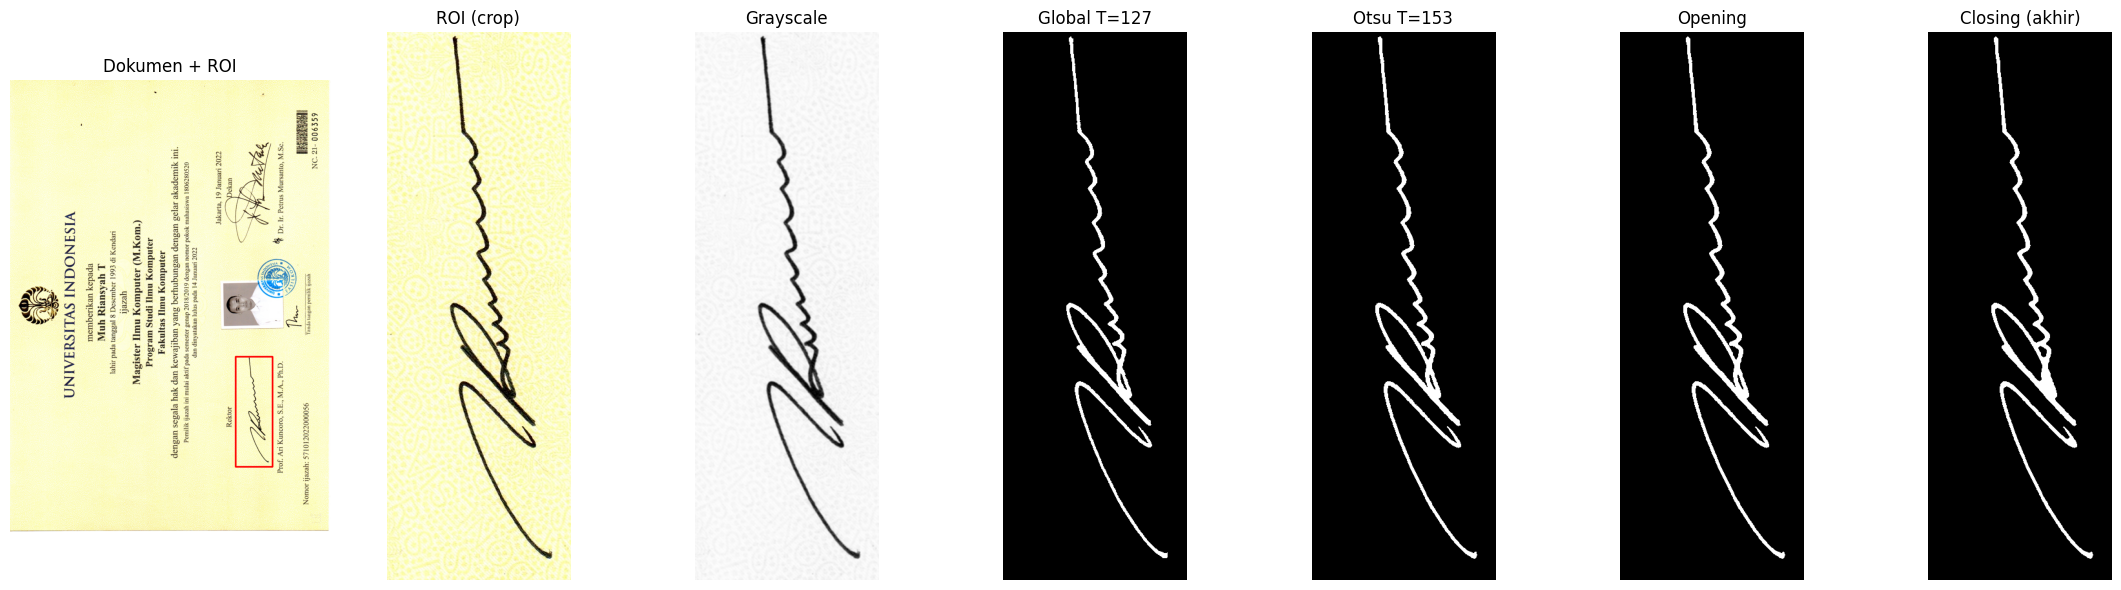

{'fg_pixels': 9777, 'ratio_pct': 4.026439337781072, 'n_components': 2, 'largest_cc': 7034} -> SIGNATURE PRESENT


In [4]:
img  = cv2.imread(f"{DATA_DIR}/01_HighQuality_Enhanced.jpg")
roi  = crop_roi(img)
gray = to_gray(roi)
_, bg = thr_global(gray)
T_raw, T_otsu, bo = thr_otsu(gray)
opened, closed = morph_clean(bo)

# Tampilkan lokasi ROI pada dokumen utuh
H, W = img.shape[:2]; x0, x1, y0, y1 = ROI
vis = img.copy()
cv2.rectangle(vis, (int(x0*W), int(y0*H)), (int(x1*W), int(y1*H)), (0, 0, 255), 12)

fig, ax = plt.subplots(1, 7, figsize=(22, 6))
steps = [("Dokumen + ROI", cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)),
         ("ROI (crop)", cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)),
         ("Grayscale", gray), (f"Global T={GLOBAL_T}", bg),
         (f"Otsu T={T_otsu:.0f}", bo), ("Opening", opened), ("Closing (akhir)", closed)]
for a, (t, im) in zip(ax, steps):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(f"{HASIL_DIR}/pipeline_demo.png", dpi=110); plt.show()
print(area_features(closed), "->", decide(area_features(closed)))

## 5. Perbandingan Metode Thresholding (Global vs Otsu vs Adaptive)
Untuk setiap citra dihitung rasio foreground (%) pada ROI. Nilai yang **diharapkan**: citra bertanda tangan ≈ 4%, citra kosong ≈ 0%.

In [5]:
rows = []
for f in files:
    name = os.path.splitext(os.path.basename(f))[0]
    g = to_gray(crop_roi(cv2.imread(f)))
    _, bg = thr_global(g)
    T_raw, T_o, bo = thr_otsu(g)
    T_otsu_murni = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
    ba = thr_adaptive(g)
    rows.append({"Sampel": name,
                 "Otsu T (murni)": int(T_raw), "Otsu T (dibatasi)": int(T_o),
                 "Global %": (bg > 0).mean()*100,
                 "Otsu murni %": (T_otsu_murni > 0).mean()*100,
                 "Otsu dibatasi %": (bo > 0).mean()*100,
                 "Adaptive %": (ba > 0).mean()*100})
df_cmp = pd.DataFrame(rows).round(2)
df_cmp.to_csv(f"{HASIL_DIR}/perbandingan_threshold.csv", index=False)
df_cmp

,Sampel,Otsu T (murni),Otsu T (dibatasi),Global %,Otsu murni %,Otsu dibatasi %,Adaptive %
0,01_HighQuality_Enhanced,153,153,3.60,3.95,3.95,4.17
1,02_LowContrast,195,195,0.62,3.96,3.96,3.98
2,03_Blurred,192,192,1.92,5.60,5.60,5.04
3,04_HighNoise,160,160,3.35,3.91,3.91,4.30
4,05_LowResolution_Upsampled,173,173,3.10,4.27,4.27,4.38
5,06_Faded_Underexposed,121,119,4.18,3.96,3.90,3.85
6,07_ColorShift_WarmTint,160,160,3.42,3.96,3.96,4.14
7,08_JPEGCompression_Artifacts,165,165,3.32,3.96,3.96,4.16
8,09_CombinedDegradation,139,139,3.81,4.20,4.20,4.16
9,10_Blank_Document,247,208,0.00,41.71,0.00,0.02


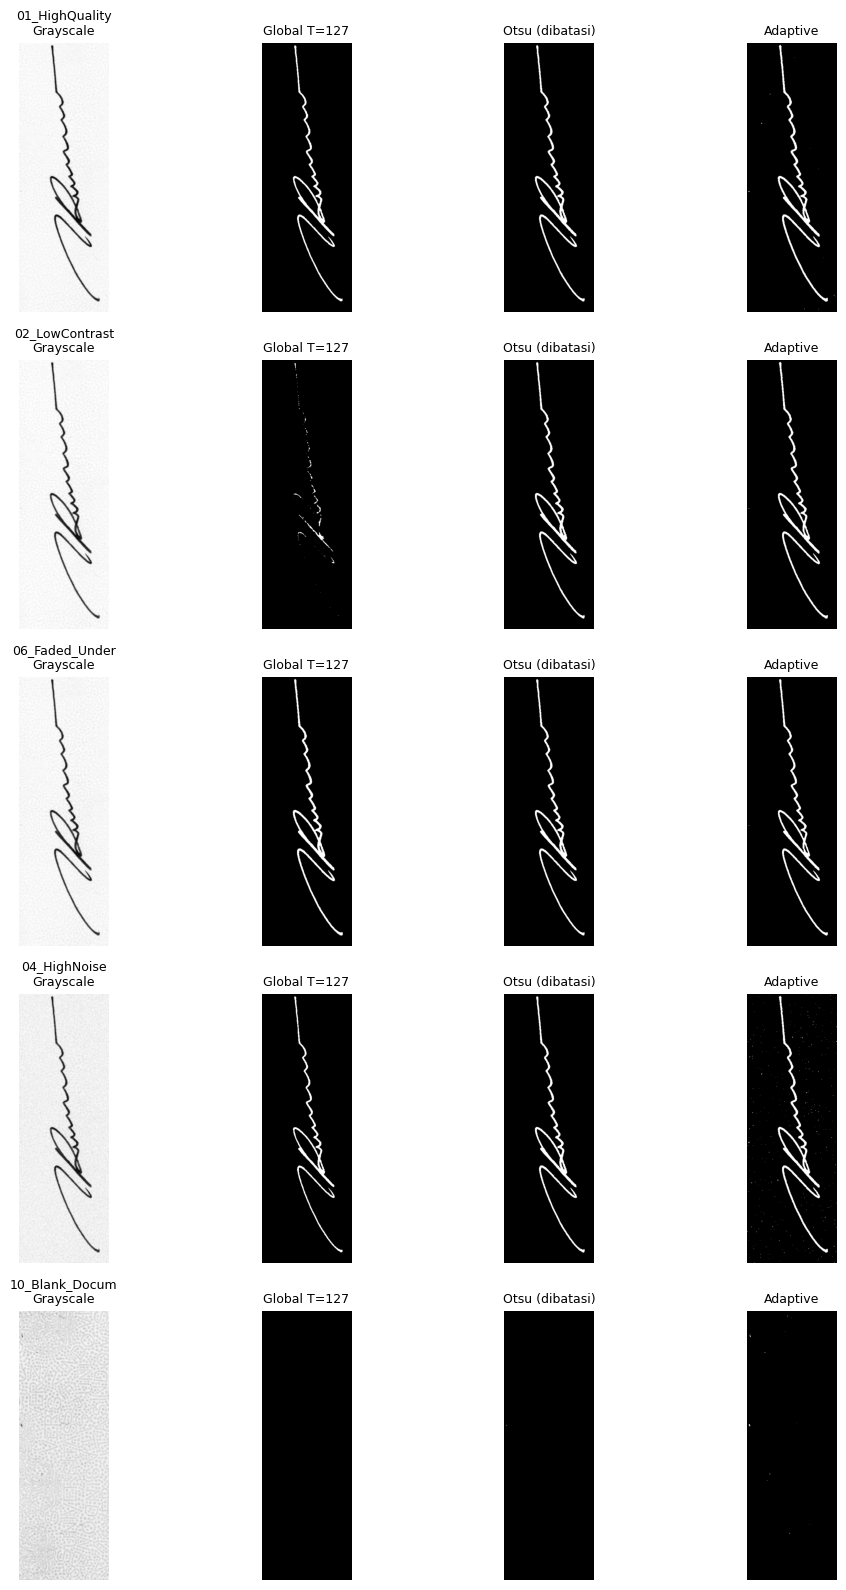

In [6]:
# Visualisasi hasil biner tiap metode untuk 5 citra representatif
pilih = ["01_HighQuality_Enhanced", "02_LowContrast", "06_Faded_Underexposed",
         "04_HighNoise", "10_Blank_Document"]
fig, ax = plt.subplots(len(pilih), 4, figsize=(11, 3.2*len(pilih)))
for r, name in enumerate(pilih):
    g = to_gray(crop_roi(cv2.imread(f"{DATA_DIR}/{name}.jpg")))
    outs = [("Grayscale", g), ("Global T=127", thr_global(g)[1]),
            ("Otsu (dibatasi)", thr_otsu(g)[2]), ("Adaptive", thr_adaptive(g))]
    for c, (t, im) in enumerate(outs):
        ax[r, c].imshow(im, cmap="gray"); ax[r, c].axis("off")
        ax[r, c].set_title(f"{name[:14]}\n{t}" if c == 0 else t, fontsize=9)
plt.tight_layout(); plt.savefig(f"{HASIL_DIR}/perbandingan_threshold.png", dpi=100); plt.show()

**Pengamatan:**
- **Global T=127** gagal pada `02_LowContrast` (hanya ~0,6% foreground karena tinta pudar tidak cukup gelap) tetapi bersih pada dokumen kosong.
- **Otsu murni** sangat baik untuk citra bertanda tangan, namun pada ROI **kosong** ia tetap membelah tekstur kertas (32–42% foreground palsu). Karena itu dipakai **Otsu dengan batas aman** (T ≤ median latar − 40).
- **Adaptive** (Gaussian, block 51, C=15) stabil pada semua citra **karena citra sudah di-blur Gaussian 3×3 lebih dulu**. Pada percobaan awal tanpa blur, metode ini sangat peka terhadap noise: rasio foreground pada `04_HighNoise` dan `12_Blank_HighNoise` melonjak ke 10–13% karena noise lokal dianggap tinta. Kelemahannya, hasilnya bergantung pada parameter block/C dan tidak punya nilai T tunggal yang mudah dijelaskan.

## 6. Pengujian Sistem Lengkap (Otsu dibatasi + Morfologi + Aturan Keputusan)

In [7]:
rows = []
for f in files:
    name = os.path.splitext(os.path.basename(f))[0]
    g = to_gray(crop_roi(cv2.imread(f)))
    T_raw, T_o, b = thr_otsu(g)
    _, closed = morph_clean(b)
    feat = area_features(closed)
    pred = decide(feat)
    truth = "SIGNATURE ABSENT" if "Blank" in name else "SIGNATURE PRESENT"
    rows.append({"Sampel": name, "Otsu T": int(T_o), "Foreground (px)": feat["fg_pixels"],
                 "Pixel Ratio (%)": round(feat["ratio_pct"], 2),
                 "Komponen": feat["n_components"], "CC Terbesar (px)": feat["largest_cc"],
                 "Ground Truth": truth, "Prediksi": pred, "Benar": pred == truth})
df = pd.DataFrame(rows)
df.to_csv(f"{HASIL_DIR}/hasil_pengujian.csv", index=False)
print(f"Akurasi: {df['Benar'].mean()*100:.1f}%  ({df['Benar'].sum()}/{len(df)} citra)")
df

Akurasi: 100.0%  (12/12 citra)


,Sampel,Otsu T,Foreground (px),Pixel Ratio (%),Komponen,CC Terbesar (px),Ground Truth,Prediksi,Benar
0,01_HighQuality_Enhanced,153,9777,4.03,2,7034,SIGNATURE PRESENT,SIGNATURE PRESENT,True
1,02_LowContrast,195,9804,4.04,2,7050,SIGNATURE PRESENT,SIGNATURE PRESENT,True
2,03_Blurred,192,13697,5.64,2,9671,SIGNATURE PRESENT,SIGNATURE PRESENT,True
3,04_HighNoise,160,9688,3.99,2,6984,SIGNATURE PRESENT,SIGNATURE PRESENT,True
4,05_LowResolution_Upsampled,173,10519,4.33,2,7536,SIGNATURE PRESENT,SIGNATURE PRESENT,True
5,06_Faded_Underexposed,119,9642,3.97,2,6958,SIGNATURE PRESENT,SIGNATURE PRESENT,True
6,07_ColorShift_WarmTint,160,9795,4.03,2,7044,SIGNATURE PRESENT,SIGNATURE PRESENT,True
7,08_JPEGCompression_Artifacts,165,9793,4.03,2,7040,SIGNATURE PRESENT,SIGNATURE PRESENT,True
8,09_CombinedDegradation,139,10358,4.27,2,7412,SIGNATURE PRESENT,SIGNATURE PRESENT,True
9,10_Blank_Document,208,0,0.00,0,0,SIGNATURE ABSENT,SIGNATURE ABSENT,True


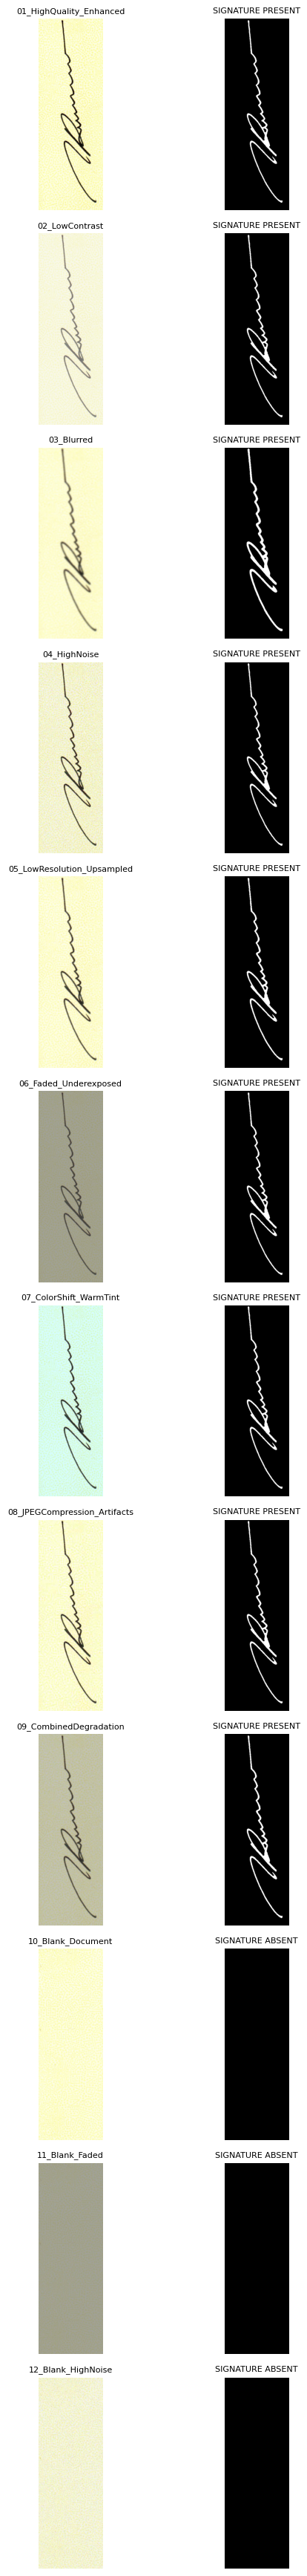

In [8]:
# Visualisasi hasil akhir tiap sampel (ROI + mask akhir + keputusan)
fig, ax = plt.subplots(len(files), 2, figsize=(7, 2.9*len(files)))
for i, f in enumerate(files):
    name = os.path.splitext(os.path.basename(f))[0]
    roi = crop_roi(cv2.imread(f)); g = to_gray(roi)
    _, closed = morph_clean(thr_otsu(g)[2])
    ax[i, 0].imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)); ax[i, 0].set_title(name, fontsize=8)
    ax[i, 1].imshow(closed, cmap="gray"); ax[i, 1].set_title(df.loc[i, "Prediksi"], fontsize=8)
    ax[i, 0].axis("off"); ax[i, 1].axis("off")
plt.tight_layout(); plt.savefig(f"{HASIL_DIR}/hasil_semua_sampel.png", dpi=90); plt.show()

## 7. Eksperimen: Efek Threshold Terlalu Rendah / Terlalu Tinggi
Nilai T disapu dari 20 sampai 250 pada tiga ROI: tanda tangan jelas (`01`), tanda tangan pudar/kontras rendah (`02`), dan kertas kosong (`10`).

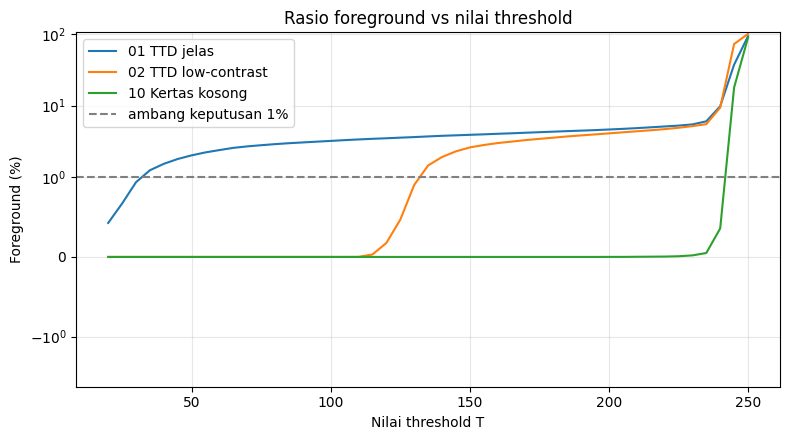

,01 TTD jelas,02 TTD low-contrast,10 Kertas kosong
60,2.40,0.00,0.00
100,3.21,0.00,0.00
125,3.57,0.47,0.00
160,4.04,3.00,0.00
200,4.64,4.09,0.00
230,5.46,5.16,0.02
250,92.63,100.00,88.33


In [9]:
sweep = list(range(20, 251, 5))
kasus = {"01 TTD jelas": "01_HighQuality_Enhanced",
         "02 TTD low-contrast": "02_LowContrast",
         "10 Kertas kosong": "10_Blank_Document"}
plt.figure(figsize=(8, 4.5))
tab = {}
for label, name in kasus.items():
    g = to_gray(crop_roi(cv2.imread(f"{DATA_DIR}/{name}.jpg")))
    ratios = [(thr_global(g, T)[1] > 0).mean()*100 for T in sweep]
    tab[label] = ratios
    plt.plot(sweep, ratios, label=label)
plt.axhline(MIN_RATIO_PCT, color="gray", ls="--", label="ambang keputusan 1%")
plt.xlabel("Nilai threshold T"); plt.ylabel("Foreground (%)"); plt.yscale("symlog", linthresh=1)
plt.title("Rasio foreground vs nilai threshold"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{HASIL_DIR}/sweep_threshold.png", dpi=110); plt.show()
pd.DataFrame(tab, index=sweep).loc[[60, 100, 125, 160, 200, 230, 250]].round(2)

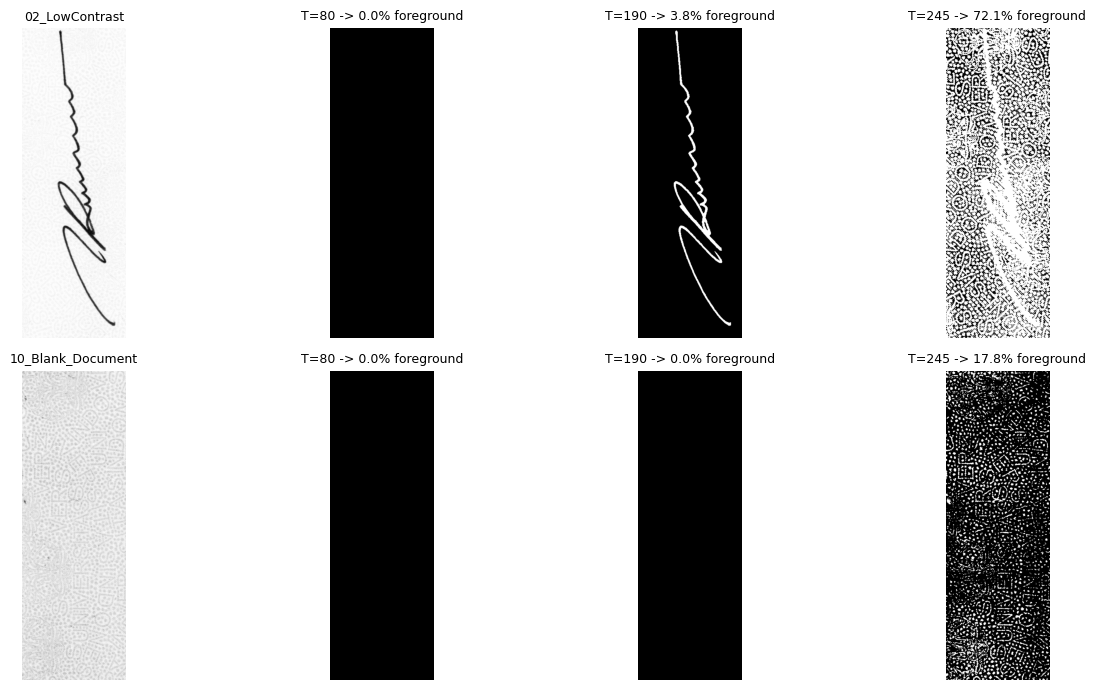

In [10]:
# Visual: threshold terlalu rendah, tepat, terlalu tinggi pada citra 02 (low contrast) & 10 (kosong)
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for r, name in enumerate(["02_LowContrast", "10_Blank_Document"]):
    g = to_gray(crop_roi(cv2.imread(f"{DATA_DIR}/{name}.jpg")))
    ax[r, 0].imshow(g, cmap="gray"); ax[r, 0].set_title(name, fontsize=9)
    for c, T in enumerate([80, 190, 245], start=1):
        b = thr_global(g, T)[1]
        ax[r, c].imshow(b, cmap="gray")
        ax[r, c].set_title(f"T={T} -> {(b>0).mean()*100:.1f}% foreground", fontsize=9)
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{HASIL_DIR}/threshold_rendah_tinggi.png", dpi=100); plt.show()

## 8. Analisis

### 1. Mengapa thresholding diperlukan sebelum menganalisis keberadaan tanda tangan?
Citra grayscale hanyalah matriks intensitas 0–255 yang berisi tinta, tekstur kertas, bayangan, dan noise sekaligus. Komputer tidak "melihat" tanda tangan; ia hanya bisa menghitung. Thresholding mengubah matriks itu menjadi citra biner sehingga **tinta (foreground) terpisah tegas dari kertas (background)**. Hanya setelah pemisahan ini, ukuran-ukuran objektif seperti jumlah piksel foreground, rasio terhadap ROI, dan luas komponen terhubung terbesar dapat dihitung dan dipakai pada aturan keputusan. Tanpa binerisasi, tekstur kertas kuning ikut terhitung dan tidak ada besaran yang bisa dibandingkan terhadap ambang.

### 2. Masalah jika threshold terlalu tinggi atau terlalu rendah?
Karena tinta lebih **gelap** dari kertas (foreground = piksel < T):
- **Threshold terlalu rendah** → hanya piksel sangat gelap yang lolos. Tinta yang pudar/tipis dan tepi goresan hilang atau terputus, ROI tampak kosong → **False Negative** (tanda tangan ada, terdeteksi tidak ada). Pada eksperimen, `02_LowContrast` dengan T=127 hanya menghasilkan ~0,6% foreground padahal seharusnya ~4%.
- **Threshold terlalu tinggi** → piksel kertas yang agak gelap (tekstur guilloche, bayangan, noise scan) ikut menjadi foreground. Rasio melonjak dan bentuk tanda tangan tertutup bercak → **False Positive** (kertas kosong terdeteksi bertanda tangan). Pada eksperimen, Otsu murni pada kertas kosong menghasilkan 32–42% foreground palsu.
- **Solusi:** nilai T ditentukan otomatis dari histogram (Otsu) dan dibatasi relatif terhadap tingkat kecerahan latar (median − 40), dilanjutkan opening untuk membuang bintik dan closing untuk menyambung goresan, serta aturan ganda (rasio ≥ 1% **dan** komponen terbesar ≥ 1500 px).

### Catatan keterbatasan
Semua 9 citra asli adalah dokumen yang sama dengan degradasi berbeda, sehingga posisi ROI identik; sampel *ABSENT* dibuat sintetis dengan menimpa area tanda tangan dengan kertas kosong. Untuk dokumen dengan posisi tanda tangan berbeda, ROI harus disesuaikan atau diperlukan deteksi lokasi otomatis.